# Analysis of Rivers

## Table of Contents

[1. Prepare Data Set](#1)

[2. Exploratory Data Analysis](#2)

[3. Time series decomposition and Random Walks](#3)
 - [1.Time series decomposition](#3-1)
 - [2.Stationarity and Hurst exponent](#3-2)
 - [3.ACF, PACF and additional time series analysis](#3-3)

## 1. Prepare Data Set<a id="1"></a>

In [1]:
import numpy as np
import pandas as pd
from datetime import datetime as dt

import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams['font.size'] = 13

In [2]:
from pathlib import Path
import sys

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data_lake" / "config.json").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root")

PROJECT_ROOT = find_project_root()
PYTHON_DIR = PROJECT_ROOT / "python"
if str(PYTHON_DIR) not in sys.path:
    sys.path.insert(0, str(PYTHON_DIR))
from utils import load_config

config_file_path = PROJECT_ROOT / "data_lake" / "config.json"

config_params = load_config(config_file_path)
bronze_folder = config_params.get('BRONZE_FOLDER', {})
indicator = config_params.get('INDICATOR', {})
river_name_column = config_params.get('RIVER_NAME_COLUMN', {})
ts_analysis_data = PROJECT_ROOT / config_params.get('TS_ANALYSIS_FOLDER', {})
bronze_folder = PROJECT_ROOT / bronze_folder
data_path = bronze_folder / 'combined_data.csv'
filter_data_path = bronze_folder / 'combined_filtered_data.csv'

In [3]:
# load data sets
chunk_iterator = pd.read_csv(data_path, chunksize=10000) 

full_data = pd.DataFrame()

for i, chunk in enumerate(chunk_iterator):
    full_data = pd.concat([full_data, chunk], ignore_index=True)

    print(f"  - Processed chunk {i+1} from {data_path}")

  - Processed chunk 1 from ../data_lake/bronze/combined/combined_data.csv
  - Processed chunk 2 from ../data_lake/bronze/combined/combined_data.csv
  - Processed chunk 3 from ../data_lake/bronze/combined/combined_data.csv
  - Processed chunk 4 from ../data_lake/bronze/combined/combined_data.csv
  - Processed chunk 5 from ../data_lake/bronze/combined/combined_data.csv


In [4]:
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48450 entries, 0 to 48449
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Post_ID        48450 non-null  int64  
 1   Post_Name      48450 non-null  object 
 2   Post_Code      47955 non-null  object 
 3   Riverbas_Name  48450 non-null  object 
 4   WaterLab_Name  48282 non-null  object 
 5   Latitude       48450 non-null  object 
 6   Longitude      48450 non-null  float64
 7   Controle_Date  48450 non-null  object 
 8   Azot           4902 non-null   object 
 9   BSK5           44165 non-null  object 
 10  Zavisli        42766 non-null  object 
 11  Kisen          44608 non-null  object 
 12  Sulfat         43496 non-null  object 
 13  Hlorid         43568 non-null  object 
 14  Amoniy         43139 non-null  object 
 15  Nitrat         42985 non-null  object 
 16  Nitrit         43061 non-null  object 
 17  Fosfat         42089 non-null  object 
 18  SPAR  

In [5]:
counts = full_data.groupby(['Post_Name', 'Riverbas_Name']).size().reset_index(name='Count')
sorted_counts = counts.sort_values('Count', ascending=False)

print(sorted_counts.head(20))

                                             Post_Name  Riverbas_Name  Count
27   канал Дніпро-Донбас, 0,5 км, с. Шульгівка, піс...         Дніпро    411
49   оз. Ялпуг-Кугурлуй, 0 км, с. Оксамитне Болград...          Дунай    318
774  р. Сіверський Донець, 522 км, м.Слов"янськ, Ра...            Дон    287
390      р. Казений Торець, 1 км, с. Райгородок, гирло            Дон    284
279  р. Дніпро, 550 км, м. Горішні Плавні (м.Комсом...         Дніпро    279
326  р. Дністер, 16 км, с. Маяки, ГНС Нижньо-Дністр...        Дністер    278
37                        оз. Кагул, 0 км, ГНС Нагірне          Дунай    274
275  р. Дніпро, 420 км, м. Дніпро, правий берег, Ка...         Дніпро    265
283  р. Дніпро, 580 км, с.Власівка, лівий берег, пи...         Дніпро    260
273  р. Дніпро, 404 км, м. Дніпро, ВП "ПдТЄС" ПАТ "...         Дніпро    260
682  р. Случ, 203 км, м. Новоград-Волинський, питни...         Дніпро    257
70   р. Інгул, 318 км, м. Кропивницький, питний в/з...  Південний Буг    254

In [6]:
filtered_data = pd.read_csv(filter_data_path)

river = filtered_data[river_name_column].iloc[0]

# print datasets general info
filtered_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 411 entries, 0 to 410
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Post_ID        411 non-null    int64  
 1   Post_Name      411 non-null    object 
 2   Post_Code      411 non-null    object 
 3   Riverbas_Name  411 non-null    object 
 4   WaterLab_Name  411 non-null    object 
 5   Latitude       411 non-null    float64
 6   Longitude      411 non-null    float64
 7   Controle_Date  411 non-null    object 
 8   Azot           0 non-null      float64
 9   BSK5           410 non-null    float64
 10  Zavisli        411 non-null    float64
 11  Kisen          410 non-null    float64
 12  Sulfat         409 non-null    float64
 13  Hlorid         411 non-null    float64
 14  Amoniy         409 non-null    float64
 15  Nitrat         409 non-null    float64
 16  Nitrit         409 non-null    float64
 17  Fosfat         409 non-null    float64
 18  SPAR      

In [7]:
required_columns = {'Controle_Date', river_name_column, indicator}
missing_columns = required_columns.difference(filtered_data.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')

duplicate_count = int(filtered_data.duplicated().sum())
if duplicate_count:
    raise ValueError(f'Filtered data contains {duplicate_count} duplicate rows')

## 2. Exploratory Data Analysis<a id="2"></a>

In [8]:
# change date values from string to datetime object
date_formats = [
    '%Y-%m-%d',
    '%d.%m.%Y'
]

filtered_data['_Raw_Date_String'] = filtered_data['Controle_Date'].astype(str)

filtered_data['Controle_Date'] = pd.to_datetime(
    filtered_data['_Raw_Date_String'],
    format=date_formats[0],
    errors='coerce'
)

for fmt in date_formats[1:]:
    mask = filtered_data['Controle_Date'].isna()

    if not mask.any():
        break

    raw_data_to_parse = filtered_data.loc[mask, '_Raw_Date_String']

    parsed_subset = pd.to_datetime(raw_data_to_parse, format=fmt, errors='coerce')

    filtered_data.loc[mask, 'Controle_Date'] = parsed_subset

filtered_data.drop(columns=['_Raw_Date_String'], inplace=True)

filtered_data = filtered_data.rename(columns={'Controle_Date': 'date'})

print(filtered_data['date'])

0     2004-02-20
1     2005-12-12
2     2006-07-12
3     2006-07-21
4     2006-08-10
         ...    
406   2018-06-19
407   2018-07-03
408   2018-07-16
409   2018-08-02
410   2018-08-21
Name: date, Length: 411, dtype: datetime64[ns]


In [9]:
filtered_data = filtered_data.sort_values('date', ascending=True)
filtered_data.dropna(subset=[f'{indicator}'], inplace=True)

print(filtered_data['date'])

78    2003-01-14
79    2003-01-22
80    2003-02-11
81    2003-02-24
82    2003-03-11
         ...    
354   2018-10-24
355   2018-11-05
356   2018-11-22
357   2018-12-04
358   2018-12-20
Name: date, Length: 410, dtype: datetime64[ns]


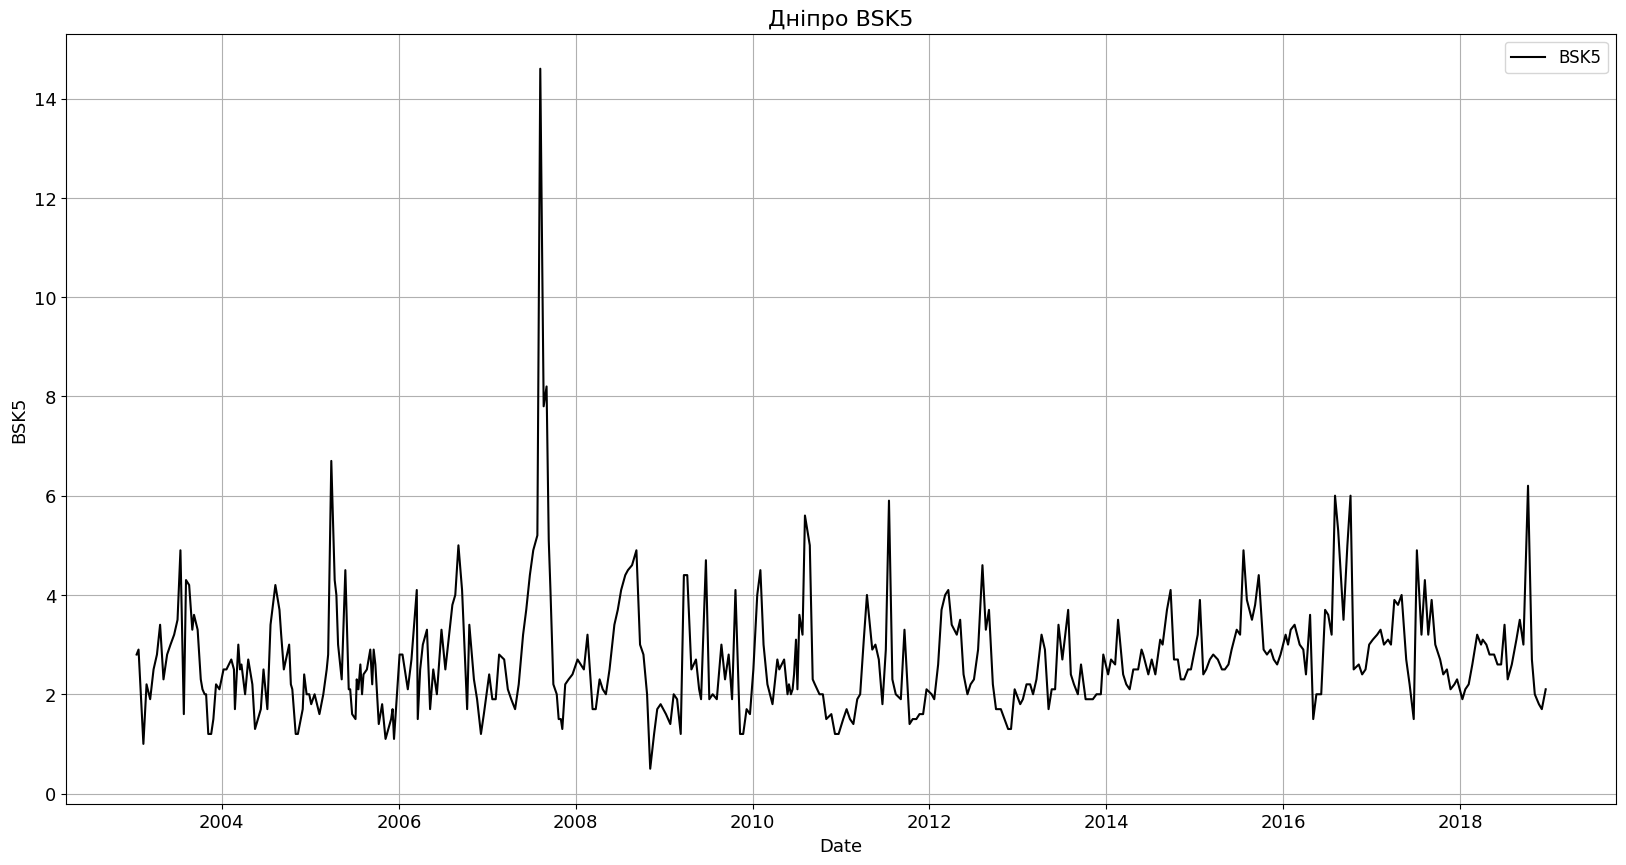

In [10]:
def plot():
    fig, ax = plt.subplots(figsize=(20,10))

    ax.plot(filtered_data['date'], filtered_data[f'{indicator}'], color='black', label=f'{indicator}')

    ax.legend(prop={"size":12})
    #ax.set_facecolor('#383838')
    ax.set_ylabel(f'{indicator}')
    ax.set_xlabel('Date')  
    ax.set_title(f'{river} {indicator}',
          fontsize=16)
    ax.grid(True)

    fig.savefig(f"{ts_analysis_data}/{river}_{indicator}.png", dpi=300, bbox_inches='tight')

plot()

In [11]:
filtered_data.head()

,Post_ID,Post_Name,Post_Code,Riverbas_Name,WaterLab_Name,Latitude,Longitude,date,Azot,BSK5,...,Amoniy,Nitrat,Nitrit,Fosfat,SPAR,Permanganat,HSK,Fitoplan,Atrazin,Simazin
78,27063,"канал Дніпро-Донбас, 0,5 км, с. Шульгівка, піс...",ЧЕР ДНЕПР 0490 0000 0000 0000 0000 0001 01 12,Дніпро,Лабораторія моніторингу вод Управління каналу ...,48.738889,34.313889,2003-01-14,NaN,2.8,...,0.34,0.50,0.021,0.40,NaN,7.1,NaN,NaN,NaN,NaN
79,27063,"канал Дніпро-Донбас, 0,5 км, с. Шульгівка, піс...",ЧЕР ДНЕПР 0490 0000 0000 0000 0000 0001 01 12,Дніпро,Лабораторія моніторингу вод Управління каналу ...,48.738889,34.313889,2003-01-22,NaN,2.9,...,0.36,2.24,0.020,0.45,NaN,7.1,NaN,NaN,NaN,NaN
80,27063,"канал Дніпро-Донбас, 0,5 км, с. Шульгівка, піс...",ЧЕР ДНЕПР 0490 0000 0000 0000 0000 0001 01 12,Дніпро,Лабораторія моніторингу вод Управління каналу ...,48.738889,34.313889,2003-02-11,NaN,1.0,...,0.15,14.20,0.020,0.41,NaN,7.4,NaN,NaN,NaN,NaN
81,27063,"канал Дніпро-Донбас, 0,5 км, с. Шульгівка, піс...",ЧЕР ДНЕПР 0490 0000 0000 0000 0000 0001 01 12,Дніпро,Лабораторія моніторингу вод Управління каналу ...,48.738889,34.313889,2003-02-24,NaN,2.2,...,0.20,5.08,0.020,0.37,NaN,7.5,NaN,NaN,NaN,NaN
82,27063,"канал Дніпро-Донбас, 0,5 км, с. Шульгівка, піс...",ЧЕР ДНЕПР 0490 0000 0000 0000 0000 0001 01 12,Дніпро,Лабораторія моніторингу вод Управління каналу ...,48.738889,34.313889,2003-03-11,NaN,1.9,...,0.31,3.70,0.022,0.38,NaN,7.5,NaN,NaN,NaN,NaN


## 3. Time series decomposition and Random Walks<a id="3"></a>

In [12]:
filtered_data.reset_index(drop=True) 
filtered_data.set_index('date', inplace = True)

In [13]:
indicator_data = filtered_data[[f'{indicator}']]
indicator_data = indicator_data.dropna()

* ### Time series decomposition<a id="3-1"></a>

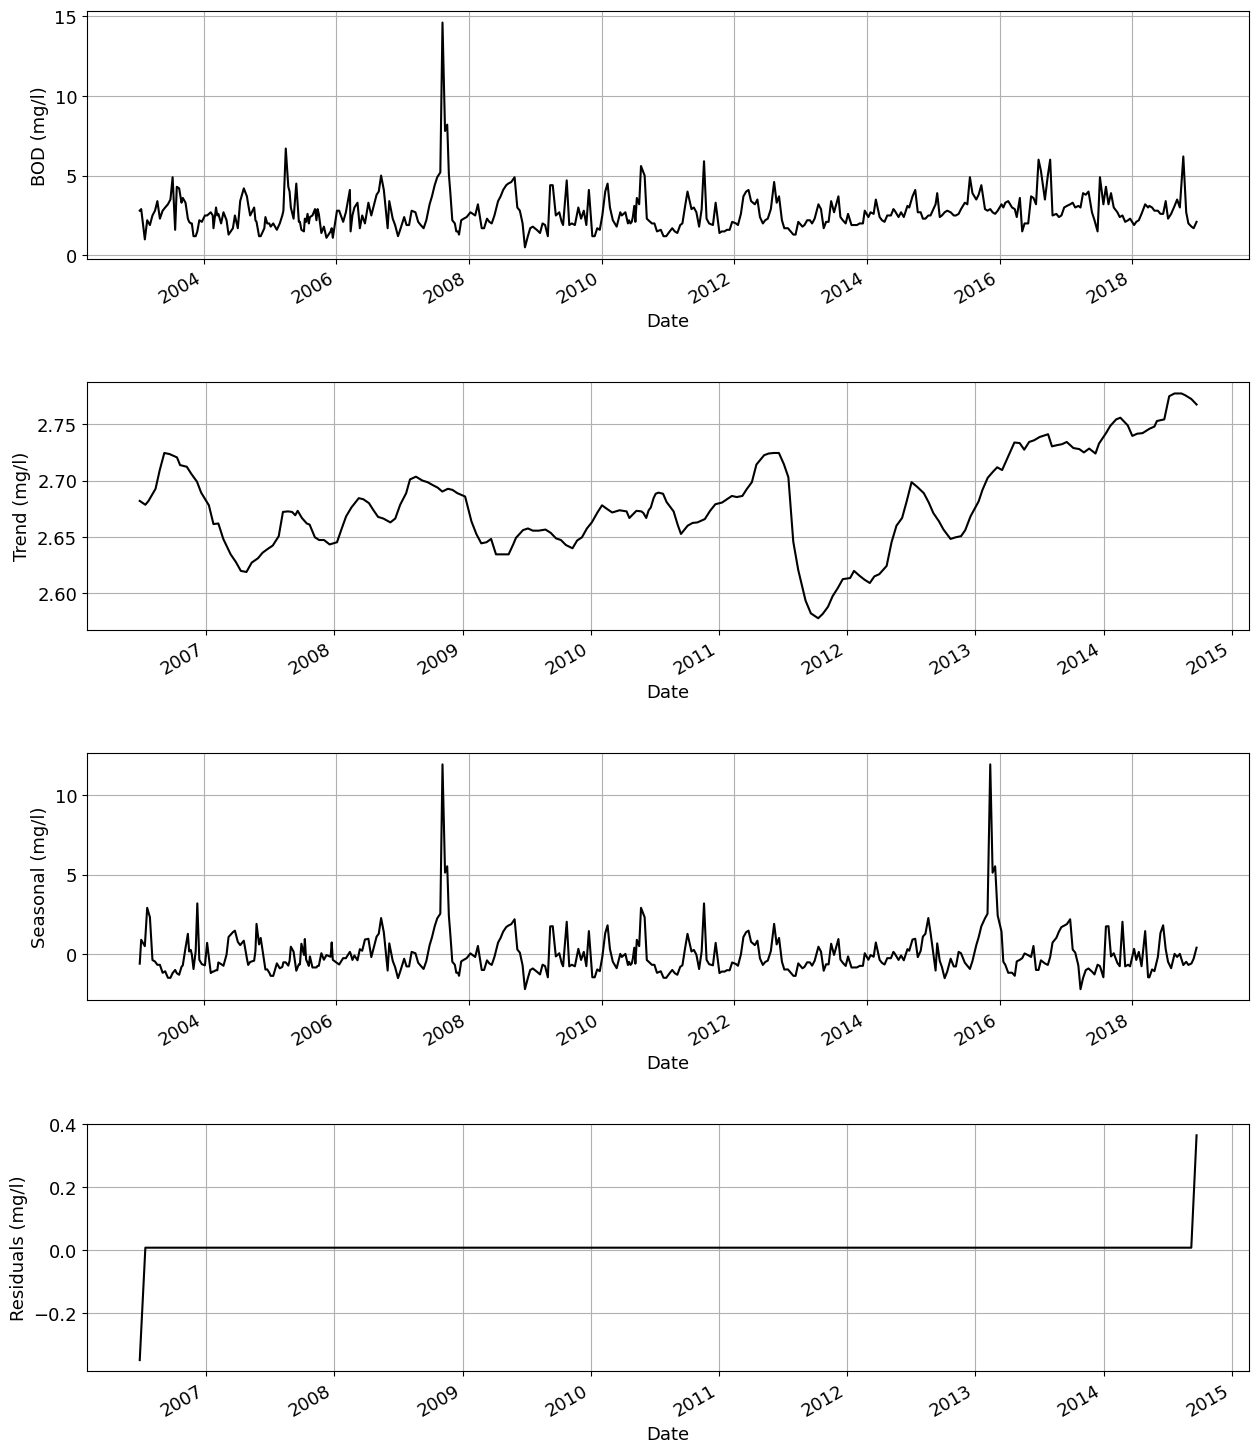

In [14]:
import statsmodels.api as sm

decomposed_ts = sm.tsa.seasonal_decompose(indicator_data, period=len(indicator_data)//2)

# Customizing the plot
fig, axes = plt.subplots(4, 1, figsize=(15, 20))

# Changing colors for different components
decomposed_ts.observed.plot(ax=axes[0], color='black', label=f'{indicator}')
#axes[0].set_ylabel(f'{indicator}')
axes[0].set_ylabel('BOD (mg/l)')
axes[0].set_xlabel('Date')
axes[0].grid(True)
#axes[0].set_facecolor('#4d4d4d')

decomposed_ts.trend.plot(ax=axes[1], color='black', label='Trend')
axes[1].set_ylabel('Trend (mg/l)')
axes[1].set_xlabel('Date')
axes[1].grid(True)
#axes[1].set_facecolor('#4d4d4d')

decomposed_ts.seasonal.plot(ax=axes[2], color='black', label='Seasonal')
axes[2].set_ylabel('Seasonal (mg/l)')
axes[2].set_xlabel('Date')
axes[2].grid(True)
#axes[2].set_facecolor('#4d4d4d')

decomposed_ts.resid.plot(ax=axes[3], color='black', label='Residuals')
axes[3].set_ylabel('Residuals (mg/l)')
axes[3].set_xlabel('Date')
axes[3].grid(True)
#axes[3].set_facecolor('#4d4d4d')

plt.subplots_adjust(wspace=0, hspace=0.5)
plt.savefig(f"{ts_analysis_data}/{river}_{indicator}_decomposition.png", dpi=300, bbox_inches='tight')
plt.show()

* ### Stationarity and Hurst exponent<a id="3-2"></a>

In [15]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import kpss

# Augmented Dickey-Fuller test
adf = adfuller(indicator_data)
print(f"ADF p-значення {river} {indicator}: {float(adf[1])}")

# KPSS test
kpss = kpss(indicator_data, regression='ct')
print(f"KPSS p-значення {river} {indicator}: {float(kpss[1])}")

ADF p-значення Дніпро BSK5: 7.082294782799317e-13
KPSS p-значення Дніпро BSK5: 0.1


Notebook warning path omitted
look-up table. The actual p-value is greater than the p-value returned.

  kpss = kpss(indicator_data, regression='ct')


* #### Rescaled range analysis (Hurst exponent)

In [16]:
indicator_val = np.concatenate(indicator_data.values, axis=0)

def get_hurst_exponent_r_s(time_series):
    """Returns the Hurst Exponent of the time series using R/S analysis"""
    time_series = list(time_series)
    N = len(time_series)
    R_S_dict = []
    
    for k in range(10, int(np.floor(N/2))+1):
        R, S = 0, 0
        
        # split time_series into subsets
        subset_list = [time_series[i:i+k] for i in range(0, N, k)]
        
        if np.mod(N, k) > 0:
            subset_list.pop()
     
        # calc mean of every subset
        mean_list=[np.mean(x) for x in subset_list]
        
        for i in range(len(subset_list)):
            cumsum_list = pd.Series(subset_list[i] - mean_list[i]).cumsum() # type: ignore
            R += max(cumsum_list) - min(cumsum_list)
            S += np.std(subset_list[i])
            
        R_S_dict.append({"R":R/len(subset_list), "S":S/len(subset_list), "n":k})
        
    log_R_S, log_n = [], []
 
    for i in range(len(R_S_dict)):
        R_S = (R_S_dict[i]["R"]) / (R_S_dict[i]["S"])
        
        log_R_S.append(np.log(R_S))
        log_n.append(np.log(R_S_dict[i]["n"]))

    reg = np.polyfit(log_n, log_R_S, 1)
    
    return reg[0]

hurst_exp = get_hurst_exponent_r_s(indicator_val)
print(f"Експонента Херста з використанням R/S аналізу: {hurst_exp:.4f}")

Експонента Херста з використанням R/S аналізу: 0.5993


* ### ACF, PACF and additional time series analysis<a id="3-3"></a>

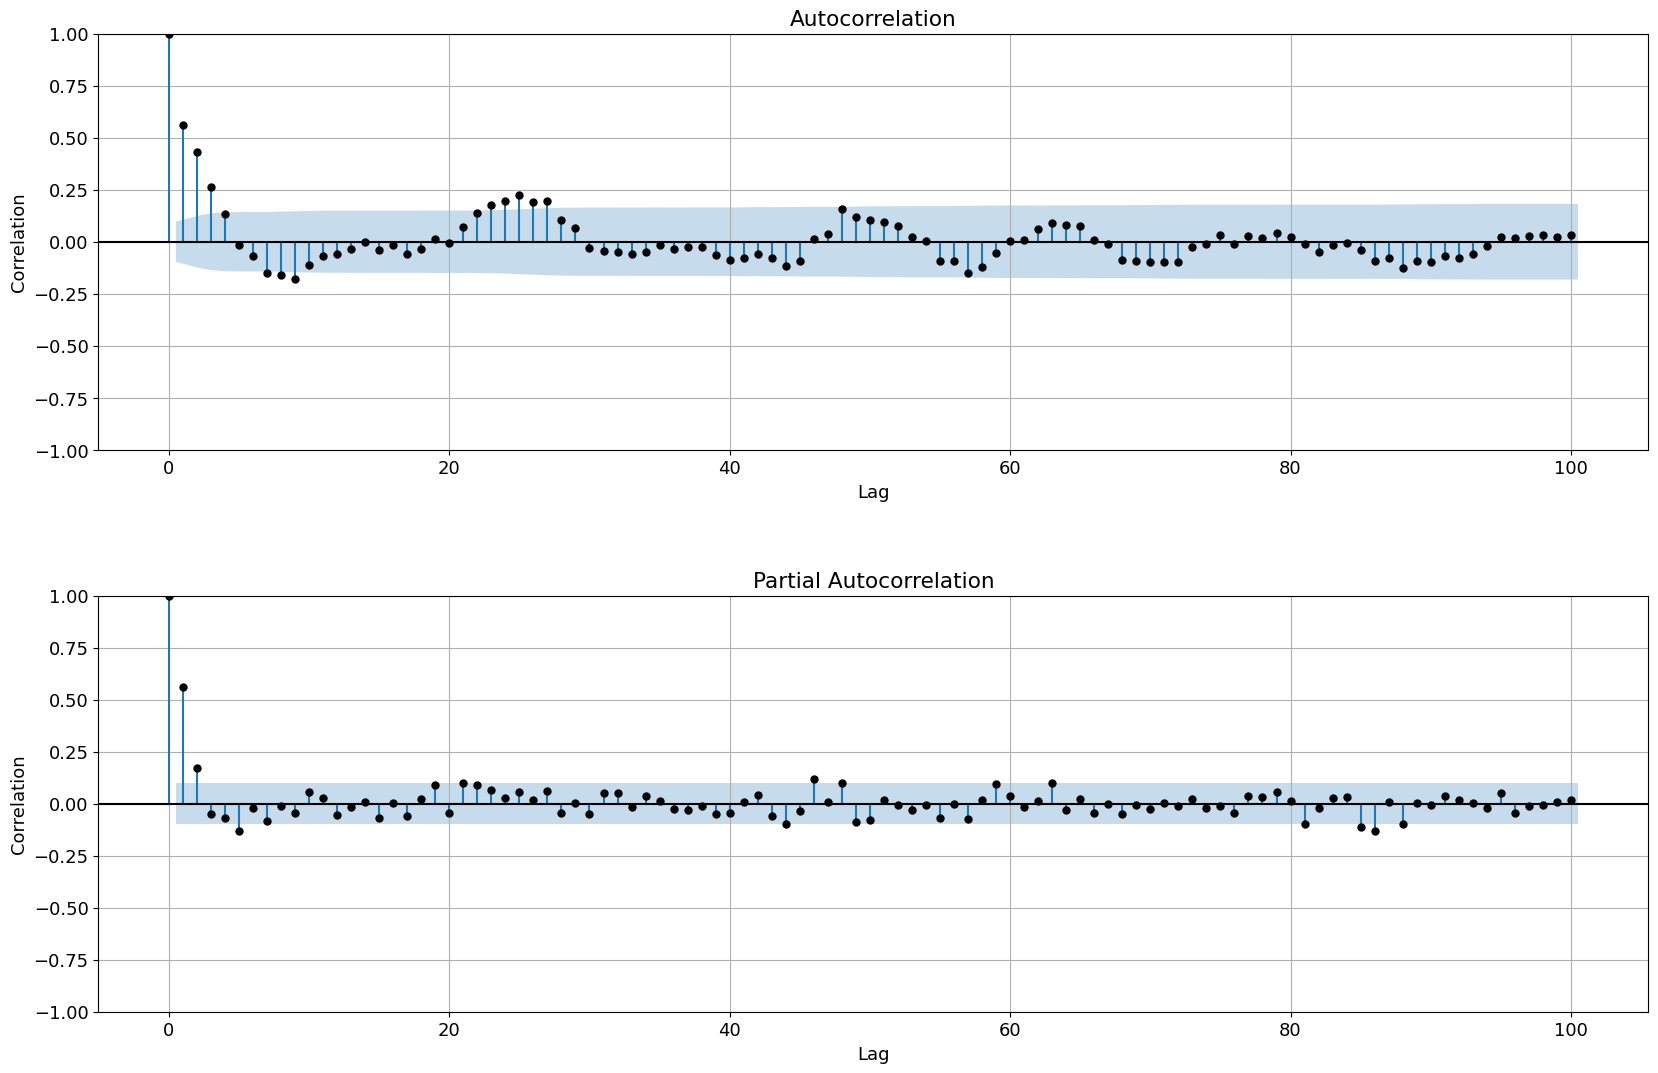

In [17]:
import statsmodels.api as sm

plt.figure(figsize=(20, 20))
ax = plt.subplot(311)
sm.graphics.tsa.plot_acf(indicator_data.values, lags=100, color='orange', ax=ax)
ax.set_ylabel('Correlation')
ax.set_xlabel('Lag')
ax.set_title('Autocorrelation')
ax.grid(True)
#axes[0].set_facecolor('#4d4d4d')

ax.lines[0].set_color('black')  # Change the color of the zero-lag line
for line in ax.lines[1:]:  # Change confidence interval lines
    line.set_color('black')
    
ax = plt.subplot(312)
sm.graphics.tsa.plot_pacf(indicator_data.values, lags=100, ax=ax)
ax.set_ylabel('Correlation')
ax.set_xlabel('Lag')
ax.set_title('Partial Autocorrelation')
ax.grid(True)

ax.lines[0].set_color('black')  # Change the color of the zero-lag line
for line in ax.lines[1:]:  # Change confidence interval lines
    line.set_color('black')
    
plt.subplots_adjust(wspace=0, hspace=0.35)
plt.savefig(f"{ts_analysis_data}/{river}_{indicator}_acf_pacf.png", dpi=300, bbox_inches='tight')
plt.show() 

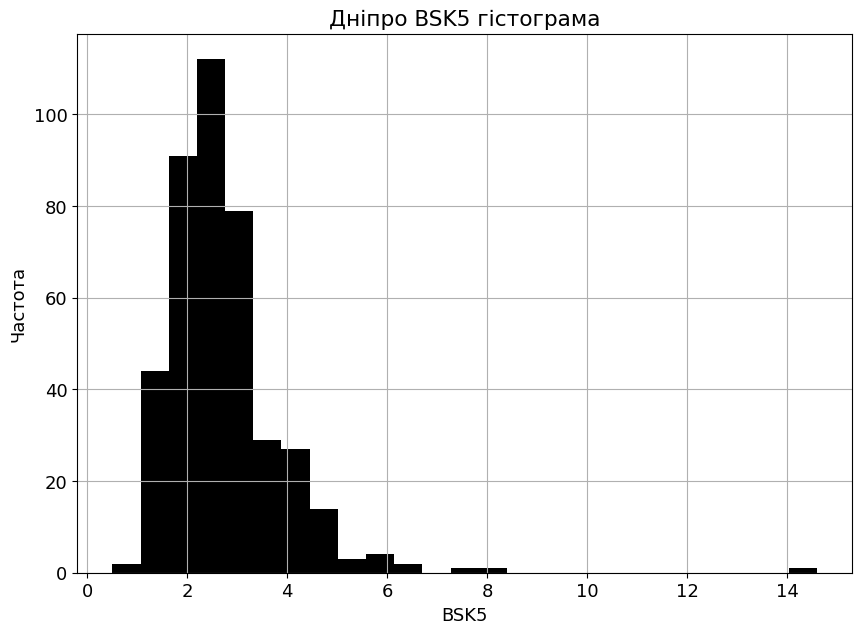

In [18]:
fig, ax = plt.subplots(figsize=(10,7))
indicator_data.hist(ax=ax, bins=25, color="black")
ax.set_xlabel(f"{indicator}")
ax.set_ylabel("Частота")
#ax.set_facecolor('#383838')
ax.set_title(f"{river} {indicator} гістограма")
fig.savefig(f"{ts_analysis_data}/{river}_{indicator}_гістограма.png", dpi=300, bbox_inches='tight')

In [19]:
indicator_stats = indicator_data.describe()
print(indicator_stats)

             BSK5
count  410.000000
mean     2.724634
std      1.195388
min      0.500000
25%      2.000000
50%      2.500000
75%      3.200000
max     14.600000
